# 03 · Baselines: predecir el ADNC del donante

Primeros modelos de verdad sobre los pseudobulk **igualados en profundidad**. Antes de cualquier GNN hay que saber
cuánto acierta un modelo sencillo: si la GNN no lo supera, el grafo no aporta.

**Diseño**

- **Un modelo por tipo celular.** Tras igualar, no todos los donantes tienen los 6 tipos, así que cada modelo usa
  los donantes que tienen ese tipo. Responde a: *¿qué tipo celular predice mejor el estadio?*
- **Fusión tardía.** Para cada donante se promedian las probabilidades de los modelos de los tipos que tiene.
- **Modelos:** regresión logística con regularización L2 (la fuerza se elige con una validación interna) y
  random forest, sobre el log-CPM de los 2.000 genes más variables del tipo.
- **Controles:** el azar (siempre High) y el modelo trampa (solo número de células y recuentos).

**Sin fuga de información:** qué genes están expresados, cuáles son los más variables y el escalado se calculan
**solo con los donantes de entrenamiento** de cada pliegue (todo va dentro de un `Pipeline`).

**Ejecución** (~5 min): `jupyter nbconvert --to notebook --execute --inplace notebooks\03_baselines.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import baselines as B
from tfm import evaluation as E
from tfm.config import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB, EV, BL = cfg["columns"], cfg["pseudobulk"], cfg["evaluation"], cfg["baselines"]
ORDEN, SEED = cfg["labels"]["classification"], cfg["seed"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

pb = ad.read_h5ad(ROOT / PB["file"])
pb_ig = ad.read_h5ad(ROOT / PB["file_igualado"])
datos, y = B.build_type_data(pb_ig, pb, cfg)
print(f"{len(y)} donantes:", y.value_counts().reindex(ORDEN).to_dict())
n_por_tipo = pd.DataFrame({t: c.index.map(y).value_counts() for t, (c, _) in datos.items()}).T.reindex(columns=ORDEN)
n_por_tipo["total"] = n_por_tipo.sum(1)
display(n_por_tipo)

74 donantes: {'Low': 12, 'Intermediate': 21, 'High': 41}


,Low,Intermediate,High,total
AST,12,20,32,64
L2IT-GLU,12,20,31,63
MGC,12,20,31,63
OLG,11,20,29,60
SST-GABA,12,21,30,63
VIP-GABA,12,21,33,66


## 1. Modelos

| Nombre | Entrada | Modelo |
|---|---|---|
| `trampa (técnicas)` | log n_celulas y log recuentos originales del tipo | logística |
| `logística (expresión)` | log-CPM de los 2.000 genes más variables | logística L2, fuerza elegida por CV interna |
| `random forest (expresión)` | lo mismo | 500 árboles |

Las particiones son las mismas para todos los modelos (5 pliegues estratificados por clase × 10 repeticiones),
así que las diferencias entre modelos no se deben a la suerte del reparto.

In [2]:
def logistica_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech), StandardScaler(),
                         LogisticRegressionCV(Cs=BL["logistica_Cs"], cv=3, max_iter=5000, class_weight="balanced",
                                              random_state=SEED))

def rf_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech),
                         RandomForestClassifier(BL["rf_arboles"], min_samples_leaf=BL["rf_min_hojas"],
                                                class_weight="balanced", n_jobs=-1, random_state=SEED))

def logistica_tec(n_tech):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))

MODELOS = {
    "trampa (técnicas)": (logistica_tec, "tecnicas"),
    "logística (expresión)": (logistica_expr, "expresion"),
    "random forest (expresión)": (rf_expr, "expresion"),
}
splits = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats_baselines"], seed=SEED)
metricas, probas = B.run_baselines(datos, y, splits, MODELOS, ORDEN)
guardar(metricas, "baselines_metricas_por_repeticion")

  AST        trampa (técnicas)                 0 s


  AST        logística (expresión)            19 s


C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklea

C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklea

C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklea

C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklea

... (269 outputs left out)

C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
C:\Users\ori\anaconda3\envs\tfm-medal\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundanc

  VIP-GABA   logística (expresión)           283 s


  VIP-GABA   random forest (expresión)       319 s


,repeticion,tipo,modelo,n_donantes,balanced_accuracy,f1_macro,kappa_cuadratico
0,0,AST,trampa (técnicas),64,0.479167,0.465751,0.473201
1,1,AST,trampa (técnicas),64,0.461806,0.452524,0.473201
2,2,AST,trampa (técnicas),64,0.506250,0.494351,0.497703
3,3,AST,trampa (técnicas),64,0.523611,0.505263,0.546269
4,4,AST,trampa (técnicas),64,0.506250,0.493351,0.505279
...,...,...,...,...,...,...,...
175,5,VIP-GABA,random forest (expresión),66,0.435786,0.395094,0.129496
176,6,VIP-GABA,random forest (expresión),66,0.352092,0.309460,0.105189
177,7,VIP-GABA,random forest (expresión),66,0.404040,0.358579,0.235890
178,8,VIP-GABA,random forest (expresión),66,0.393939,0.350111,0.215429


## 2. Resultados por tipo celular

Balanced accuracy: media del acierto en cada clase (azar = 0,33). Kappa cuadrático: acuerdo que tiene en cuenta
el orden Low < Intermediate < High (azar = 0). La desviación es entre las 10 repeticiones de la validación
cruzada: mide la estabilidad frente al reparto de donantes, no la incertidumbre total.

In [3]:
por_tipo = guardar(B.summarize_by(metricas), "baselines_por_tipo")
tabla = por_tipo["balanced_accuracy_media"].unstack("modelo")[list(MODELOS)]
tabla_k = por_tipo["kappa_cuadratico_media"].unstack("modelo")[list(MODELOS)]
print("Balanced accuracy"); display(tabla.round(3))
print("Kappa cuadrático"); display(tabla_k.round(3))

Balanced accuracy


modelo,trampa (técnicas),logística (expresión),random forest (expresión)
tipo,,,
AST,0.501,0.388,0.371
L2IT-GLU,0.657,0.385,0.357
MGC,0.531,0.350,0.333
OLG,0.462,0.327,0.351
SST-GABA,0.519,0.384,0.354
VIP-GABA,0.565,0.354,0.385


Kappa cuadrático


modelo,trampa (técnicas),logística (expresión),random forest (expresión)
tipo,,,
AST,0.495,0.139,0.128
L2IT-GLU,0.709,0.204,0.164
MGC,0.541,0.046,-0.019
OLG,0.445,-0.064,0.053
SST-GABA,0.541,0.076,0.092
VIP-GABA,0.606,0.176,0.152


## 3. Fusión tardía y comparación global

La fusión da una predicción para los 74 donantes. La comparamos con el azar y con el modelo trampa global (las
variables técnicas de los 6 tipos juntas), usando exactamente las mismas particiones.

In [4]:
fusion = {m: B.fuse(probas, y, ORDEN, m) for m in MODELOS}
Xt, yt = E.technical_features(pb, cfg)
Xt = Xt.reindex(y.index).fillna(0)
glob = {
    "azar (siempre High)": E.cross_validate(Xt, y, lambda: DummyClassifier(strategy="most_frequent"), splits, ORDEN)[0],
    "trampa global (6 tipos)": E.cross_validate(Xt, y, lambda: logistica_tec(0), splits, ORDEN)[0],
    **{f"fusión: {m}": f[0] for m, f in fusion.items()},
}
global_tabla = guardar(E.summarize(glob), "baselines_global")
display(global_tabla.round(3))

,balanced_accuracy_media,balanced_accuracy_sd,f1_macro_media,f1_macro_sd,kappa_cuadratico_media,kappa_cuadratico_sd
modelo,,,,,,
azar (siempre High),0.333,0.000,0.238,0.000,0.000,0.000
trampa global (6 tipos),0.638,0.023,0.623,0.026,0.685,0.023
fusión: trampa (técnicas),0.687,0.016,0.665,0.018,0.760,0.019
fusión: logística (expresión),0.385,0.022,0.346,0.025,0.115,0.035
fusión: random forest (expresión),0.378,0.023,0.338,0.026,0.119,0.040


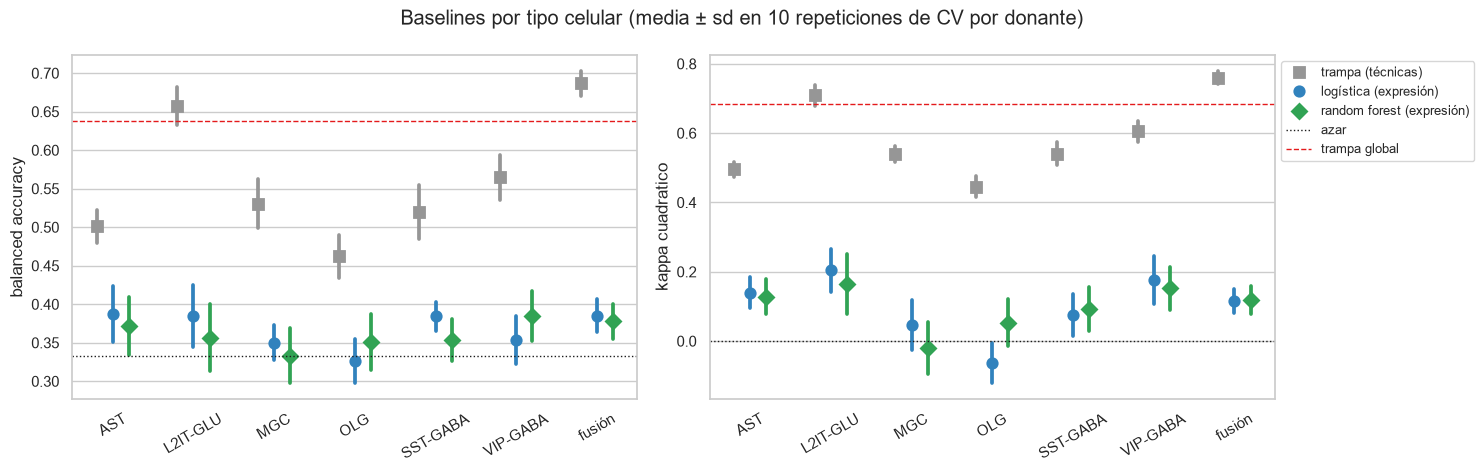

In [5]:
largo = metricas.copy()
for m, (f, _) in fusion.items():
    largo = pd.concat([largo, f])
orden_tipos = sorted(datos) + ["fusión"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)
for ax, met, azar in [(axs[0], "balanced_accuracy", 1 / 3), (axs[1], "kappa_cuadratico", 0)]:
    sns.pointplot(data=largo, x="tipo", y=met, hue="modelo", order=orden_tipos, hue_order=list(MODELOS),
                  dodge=0.4, errorbar="sd", linestyle="none", markers=["s", "o", "D"], ax=ax,
                  palette=["#969696", "#3182bd", "#31a354"])
    ax.axhline(azar, color="k", ls=":", lw=1, label="azar")
    ax.axhline(global_tabla.loc["trampa global (6 tipos)", f"{met}_media"], color="#e41a1c", ls="--", lw=1,
               label="trampa global")
    ax.set_xlabel(""); ax.set_ylabel(met.replace("_", " ")); ax.tick_params(axis="x", rotation=30)
axs[0].get_legend().remove()
axs[1].legend(bbox_to_anchor=(1, 1), fontsize=9)
fig.suptitle("Baselines por tipo celular (media ± sd en 10 repeticiones de CV por donante)")
fig.tight_layout(); guardar_fig(fig, "baselines_por_tipo"); plt.show()

## 4. ¿Dónde se equivoca?

Matriz de confusión de la fusión con regresión logística, sumando las 10 repeticiones (cada donante se predice
10 veces). Los errores entre clases vecinas (Low–Intermediate, Intermediate–High) son más tolerables que
Low–High.

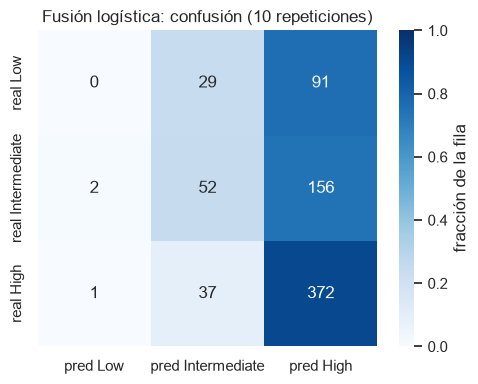

In [6]:
_, P = fusion["logística (expresión)"]
cm = sum(confusion_matrix(y.values, np.array(ORDEN)[P[r].argmax(1)], labels=ORDEN) for r in range(P.shape[0]))
cm = pd.DataFrame(cm, index=[f"real {c}" for c in ORDEN], columns=[f"pred {c}" for c in ORDEN])
guardar(cm, "baselines_confusion_fusion_logistica")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm.div(cm.sum(1), axis=0), annot=cm.values, fmt="d", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "fracción de la fila"})
ax.set_title("Fusión logística: confusión (10 repeticiones)")
fig.tight_layout(); guardar_fig(fig, "baselines_confusion"); plt.show()

## 5. ¿El modelo de expresión está usando el número de células?

Aunque igualamos los recuentos, el número de células sigue ligado a la clase. Si el modelo de expresión lo estuviera
aprendiendo de forma indirecta, su probabilidad de High subiría cuando el donante tiene pocas células **incluso
dentro de una misma clase**. Medimos la correlación de Spearman, dentro de cada clase, entre P(High) de la fusión
logística y el log del número total de células del donante. Valores cercanos a 0 son tranquilizadores.

In [7]:
p_high = pd.Series(P[:, :, ORDEN.index("High")].mean(0), index=y.index)
n_cel = pb.obs.groupby(pb.obs[COL["donor"]].astype(str), observed=True)["n_celulas"].sum().reindex(y.index)
filas = []
for c in ORDEN:
    m = (y == c).to_numpy()
    rho, pval = stats.spearmanr(np.log10(n_cel[m]), p_high[m])
    filas.append({"clase": c, "donantes": int(m.sum()), "rho_P(High)_vs_log_n_celulas": rho, "p": pval})
fuga = guardar(pd.DataFrame(filas).set_index("clase"), "baselines_comprobacion_n_celulas")
display(fuga.round(3))

,donantes,rho_P(High)_vs_log_n_celulas,p
clase,,,
Low,12,-0.245,0.443
Intermediate,21,-0.077,0.741
High,41,-0.440,0.004


In [8]:
resumen = {
    "donantes": int(len(y)), "repeticiones": EV["n_repeats_baselines"], "pliegues": EV["n_splits"],
    "balanced_accuracy_por_tipo": tabla.round(3).to_dict(),
    "kappa_por_tipo": tabla_k.round(3).to_dict(),
    "global": global_tabla[["balanced_accuracy_media", "balanced_accuracy_sd", "kappa_cuadratico_media"]].round(3).to_dict(orient="index"),
    "rho_P_high_vs_n_celulas_dentro_de_clase": fuga["rho_P(High)_vs_log_n_celulas"].round(3).to_dict(),
}
(TABLAS / "baselines_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "donantes": 74,
  "repeticiones": 10,
  "pliegues": 5,
  "balanced_accuracy_por_tipo": {
    "trampa (técnicas)": {
      "AST": 0.501,
      "L2IT-GLU": 0.657,
      "MGC": 0.531,
      "OLG": 0.462,
      "SST-GABA": 0.519,
      "VIP-GABA": 0.565
    },
    "logística (expresión)": {
      "AST": 0.388,
      "L2IT-GLU": 0.385,
      "MGC": 0.35,
      "OLG": 0.327,
      "SST-GABA": 0.384,
      "VIP-GABA": 0.354
    },
    "random forest (expresión)": {
      "AST": 0.371,
      "L2IT-GLU": 0.357,
      "MGC": 0.333,
      "OLG": 0.351,
      "SST-GABA": 0.354,
      "VIP-GABA": 0.385
    }
  },
  "kappa_por_tipo": {
    "trampa (técnicas)": {
      "AST": 0.495,
      "L2IT-GLU": 0.709,
      "MGC": 0.541,
      "OLG": 0.445,
      "SST-GABA": 0.541,
      "VIP-GABA": 0.606
    },
    "logística (expresión)": {
      "AST": 0.139,
      "L2IT-GLU": 0.204,
      "MGC": 0.046,
      "OLG": -0.064,
      "SST-GABA": 0.076,
      "VIP-GABA": 0.176
    },
    "random forest (expre